# Thiran — Proof of Concept
**Offline AI that hears machine breakdowns before they happen** · Tech4Bharat (GAVS) Hackathon · PS 4.3

The core idea: learn what a machine's **normal** vibration/sound looks like — using **no fault labels** — and flag anything that drifts away from it.

This notebook proves it on two public, real-machine datasets:
- **Part A – Vibration:** CWRU bearing dataset (motor drive-end accelerometer, healthy vs. inner-race / ball / outer-race faults)
- **Part B – Sound:** Air-compressor acoustic dataset (healthy vs. 7 fault types)
- **Stress test:** performance under increasing factory noise, to show honestly where the method starts to struggle

In both parts the model is trained **only on healthy data**. Faults are never shown during training.

Run with **Runtime → Run all**.

In [1]:
import os, glob, zipfile, urllib.request, warnings
import numpy as np, scipy.io, scipy.signal as ss
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
torch.manual_seed(0); np.random.seed(0)
os.makedirs('results', exist_ok=True)

def fetch(urls, path):
    if os.path.exists(path): return path
    for url in ([urls] if isinstance(urls, str) else urls):
        try:
            print('Downloading', url)
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r, open(path + '.part', 'wb') as f:
                f.write(r.read())
            os.replace(path + '.part', path); return path
        except Exception as e:
            print('  failed:', e)
    raise RuntimeError(f'Could not download {path}')

class AE(nn.Module):
    """Tiny autoencoder: learns to reconstruct HEALTHY patterns only."""
    def __init__(s, d, h=64, z=16):
        super().__init__()
        s.enc = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, z), nn.ReLU())
        s.dec = nn.Sequential(nn.Linear(z, h), nn.ReLU(), nn.Linear(h, d))
    def forward(s, x): return s.dec(s.enc(x))

def train_ae(X, epochs=40, bs=64, lr=1e-3):
    m = AE(X.shape[1]); opt = torch.optim.AdamW(m.parameters(), lr, weight_decay=1e-3)
    Xt = torch.tensor(X, dtype=torch.float32)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), bs):
            b = Xt[perm[i:i+bs]]
            b = b + 0.1 * torch.randn_like(b) if m.training else b   # denoising: generalise, don't memorise
            loss = ((m(b) - Xt[perm[i:i+bs]]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

def anomaly_score(m, X):
    """Reconstruction error: high = machine is behaving unlike its healthy self."""
    with torch.no_grad():
        Xt = torch.tensor(X, dtype=torch.float32)
        return ((m(Xt) - Xt) ** 2).mean(1).numpy()

def report(name, s_norm, faults, thr, persist=1):
    # persist>1: alert only when the median of that many consecutive windows crosses the threshold (ignores one-off spikes)
    hold = (lambda s: ss.medfilt(s, persist)) if persist > 1 else (lambda s: s)
    rows = []
    fa = (hold(s_norm) > thr).mean() * 100
    print(f'{name}\n' + '-' * 62)
    print(f"{'Condition':<22}{'ROC-AUC':>10}{'Detected':>14}")
    for k, s in faults.items():
        auc = roc_auc_score(np.r_[np.zeros(len(s_norm)), np.ones(len(s))], np.r_[s_norm, s])
        det = (hold(s) > thr).mean() * 100
        rows.append((k, auc, det)); print(f'{k:<22}{auc:>10.3f}{det:>13.1f}%')
    print(f"{'False alarms (healthy)':<22}{'':>10}{fa:>13.1f}%\n")
    return rows, fa

## Part A — Vibration (CWRU bearing dataset)
Healthy motor at 4 loads (0–3 HP) vs. 0.007" bearing faults. Healthy data is recorded at 48 kHz, so it is down-sampled to 12 kHz to match the fault recordings.
Each 2048-sample window → FFT → 128 log-energy bands (0–4.5 kHz, kept below the down-sampling filter so healthy and fault data are compared fairly) → autoencoder.

In [2]:
BASE = 'https://engineering.case.edu/sites/default/files/'
NORMAL = {'0 HP': 97, '1 HP': 98, '2 HP': 99, '3 HP': 100}                        # 48 kHz
FAULTS = {'Inner-race fault': 105, 'Ball fault': 118, 'Outer-race fault': 130}    # 12 kHz
os.makedirs('cwru', exist_ok=True)

def load_de(n):
    d = scipy.io.loadmat(fetch(f'{BASE}{n}.mat', f'cwru/{n}.mat'))
    keys = [k for k in d if k.endswith('_DE_time')]
    k = next((k for k in keys if k.startswith(f'X{n:03d}')), keys[0])
    return d[k].ravel().astype(np.float32)

WIN, HOP, NB = 2048, 512, 128
def fft_feats(x):
    fr = np.lib.stride_tricks.sliding_window_view(x, WIN)[::HOP] * np.hanning(WIN)
    mag = np.log1p(np.abs(np.fft.rfft(fr, axis=1))[:, :768])        # 0–4.5 kHz
    return mag.reshape(len(mag), NB, -1).mean(2).astype(np.float32)

raw_norm = {n: ss.decimate(load_de(n), 4).astype(np.float32) for n in NORMAL.values()}   # 48k -> 12k
raw_fault = {k: load_de(n) for k, n in FAULTS.items()}
tr, va, te_norm = [], [], []
for x in raw_norm.values():
    f = fft_feats(x)
    a, b = int(0.6 * len(f)), int(0.75 * len(f))                    # time split: 60% train | 15% calibrate | 25% test
    tr.append(f[:a]); va.append(f[a:b]); te_norm.append(f[b:])
tr, va, te_norm = map(np.vstack, (tr, va, te_norm))
te_fault = {k: fft_feats(x) for k, x in raw_fault.items()}

mu, sd = tr.mean(0), tr.std(0) + 1e-6
z = lambda X: (X - mu) / sd
print(f'Training windows (healthy only): {len(tr)} | test healthy: {len(te_norm)} | '
      + ' | '.join(f'{k}: {len(v)}' for k, v in te_fault.items()))

mA = train_ae(z(tr))
thrA = np.percentile(anomaly_score(mA, z(va)), 99)   # alert threshold from unseen healthy data
sA_norm = anomaly_score(mA, z(te_norm))
sA_fault = {k: anomaly_score(mA, z(v)) for k, v in te_fault.items()}
rowsA, faA = report('PART A — Vibration (CWRU)', sA_norm, sA_fault, thrA, persist=5)   # alert must persist ~5 windows (~0.2 s)

Training windows (healthy only): 487 | test healthy: 206 | Inner-race fault: 233 | Ball fault: 236 | Outer-race fault: 235


PART A — Vibration (CWRU)
--------------------------------------------------------------
Condition                ROC-AUC      Detected
Inner-race fault           1.000        100.0%
Ball fault                 1.000        100.0%
Outer-race fault           1.000        100.0%
False alarms (healthy)                    0.0%



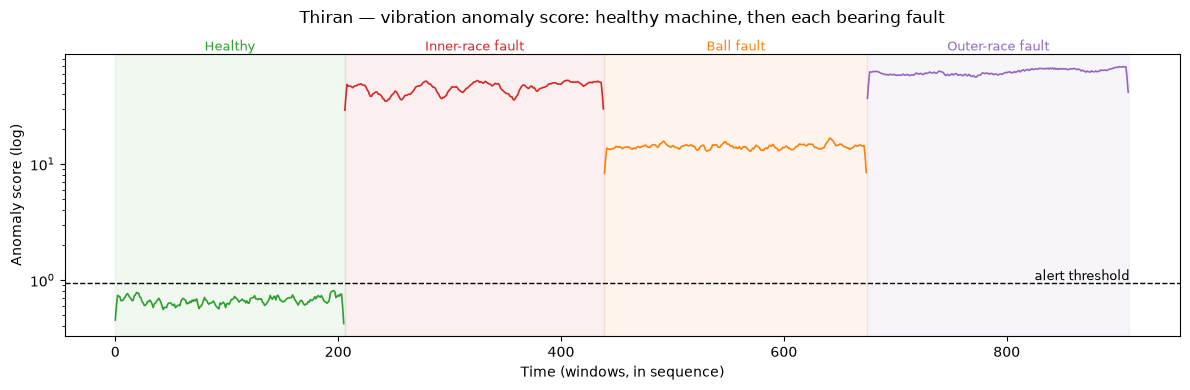

In [3]:
def timeline(s_norm, s_fault, thr, title, fname, unit='window'):
    seq = [('Healthy', s_norm)] + list(s_fault.items())
    sm = lambda s: np.convolve(s, np.ones(5) / 5, mode='same') if len(s) > 10 else s
    fig, ax = plt.subplots(figsize=(12, 4)); x0 = 0
    cols = ['tab:green', 'tab:red', 'tab:orange', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:olive', 'tab:cyan']
    for (lab, s), c in zip(seq, cols):
        xs = np.arange(x0, x0 + len(s)); ax.plot(xs, sm(s), color=c, lw=1.2)
        ax.axvspan(x0, x0 + len(s), color=c, alpha=0.07)
        ax.annotate(lab, (x0 + len(s) / 2, 1.0), xycoords=('data', 'axes fraction'),
                    ha='center', va='bottom', fontsize=9, color=c)
        x0 += len(s)
    ax.axhline(thr, ls='--', color='k', lw=1); ax.text(x0, thr, ' alert threshold', va='bottom', ha='right', fontsize=9)
    ax.set_yscale('log'); ax.set_xlabel(f'Time ({unit}s, in sequence)'); ax.set_ylabel('Anomaly score (log)')
    ax.set_title(title, pad=22); plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

timeline(sA_norm, sA_fault, thrA, 'Thiran — vibration anomaly score: healthy machine, then each bearing fault',
         'results/cwru_timeline.png')

## Part A2 — Stress test: how does it hold up in a noisy factory?
Clean lab data is easy. Real factory floors are noisy. Here we add random background noise to **every** signal at increasing levels
(SNR 10 dB = mild, 0 dB = noise as strong as the machine itself, −20 dB = noise 100× stronger than the machine) and repeat the whole process:
learn normal in the noisy environment → calibrate → detect. This shows honestly where the method starts to struggle.

SNR (dB)    Mean ROC-AUC   Detection   False alarms


10                 1.000      100.0%           0.0%


0                  1.000      100.0%           0.0%


-5                 1.000      100.0%           0.0%


-10                1.000      100.0%           0.0%


-15                0.976       82.9%           0.0%


-20                0.830       43.8%           0.0%


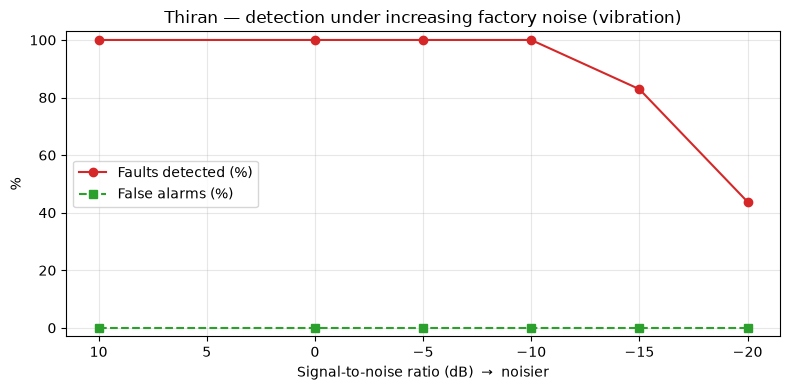

In [4]:
P = np.mean(np.concatenate(list(raw_norm.values())) ** 2)        # healthy-machine signal power
rng = np.random.default_rng(0)
noisy = lambda x, snr: (x + rng.normal(0, np.sqrt(P / 10 ** (snr / 10)), x.shape)).astype(np.float32)
hold5 = lambda s: ss.medfilt(s, 5)
SNRS = [10, 0, -5, -10, -15, -20]
rows_snr = []
print(f"{'SNR (dB)':<10}{'Mean ROC-AUC':>14}{'Detection':>12}{'False alarms':>15}")
for snr in SNRS:
    tr_, va_, te_ = [], [], []
    for x in raw_norm.values():
        f = fft_feats(noisy(x, snr)); a, b = int(0.6 * len(f)), int(0.75 * len(f))
        tr_.append(f[:a]); va_.append(f[a:b]); te_.append(f[b:])
    tr_, va_, te_ = map(np.vstack, (tr_, va_, te_))
    m_, s_ = tr_.mean(0), tr_.std(0) + 1e-6; zz = lambda X: (X - m_) / s_
    mod = train_ae(zz(tr_))
    thr = np.percentile(anomaly_score(mod, zz(va_)), 99)
    sn = anomaly_score(mod, zz(te_))
    sf = [anomaly_score(mod, zz(fft_feats(noisy(x, snr)))) for x in raw_fault.values()]
    auc = np.mean([roc_auc_score(np.r_[np.zeros(len(sn)), np.ones(len(f))], np.r_[sn, f]) for f in sf])
    det = np.mean([(hold5(f) > thr).mean() * 100 for f in sf]); fa = (hold5(sn) > thr).mean() * 100
    rows_snr.append((snr, auc, det, fa)); print(f'{snr:<10}{auc:>14.3f}{det:>11.1f}%{fa:>14.1f}%')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r[0] for r in rows_snr], [r[2] for r in rows_snr], 'o-', label='Faults detected (%)', color='tab:red')
ax.plot([r[0] for r in rows_snr], [r[3] for r in rows_snr], 's--', label='False alarms (%)', color='tab:green')
ax.invert_xaxis(); ax.set_xlabel('Signal-to-noise ratio (dB)  →  noisier'); ax.set_ylabel('%'); ax.set_ylim(-3, 103)
ax.set_title('Thiran — detection under increasing factory noise (vibration)'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig('results/noise_robustness.png', dpi=150); plt.show()

## Part B — Sound (Air-compressor acoustic dataset)
1,800 microphone recordings (16 kHz, 3 s each) of an industrial air compressor: Healthy + 7 faults (valve leaks, piston ring, flywheel, rider belt, bearing).
Log-mel spectrogram frames → autoencoder → average score per recording. If the download fails, skip this part — Part A is enough on its own.

In [5]:
import librosa
URL_B = ['https://ssd.mathworks.com/supportfiles/audio/AirCompressorDataset/AirCompressorDataset.zip',
         'https://www.mathworks.com/supportfiles/audio/AirCompressorDataset/AirCompressorDataset.zip']
os.makedirs('aircomp', exist_ok=True)
wavs = glob.glob('aircomp/**/*.wav', recursive=True)
if not wavs:
    try:
        with zipfile.ZipFile(fetch(URL_B, 'aircomp.zip')) as zf: zf.extractall('aircomp')
        wavs = glob.glob('aircomp/**/*.wav', recursive=True)
    except Exception as e:
        print('Part B download failed — skip this part.', e)
PART_B = len(wavs) > 0
print('Recordings found:', len(wavs))

Recordings found: 1800


{'Bearing': 225, 'Flywheel': 225, 'Healthy': 225, 'Inlet-valve leak': 225, 'Outlet-valve leak': 225, 'Non-return valve': 225, 'Piston ring': 225, 'Rider belt': 225}


PART B — Sound (air compressor)
--------------------------------------------------------------
Condition                ROC-AUC      Detected
Bearing                    1.000        100.0%
Flywheel                   1.000        100.0%
Inlet-valve leak           1.000        100.0%
Outlet-valve leak          1.000        100.0%
Non-return valve           1.000        100.0%
Piston ring                1.000        100.0%
Rider belt                 1.000        100.0%
False alarms (healthy)                    8.8%



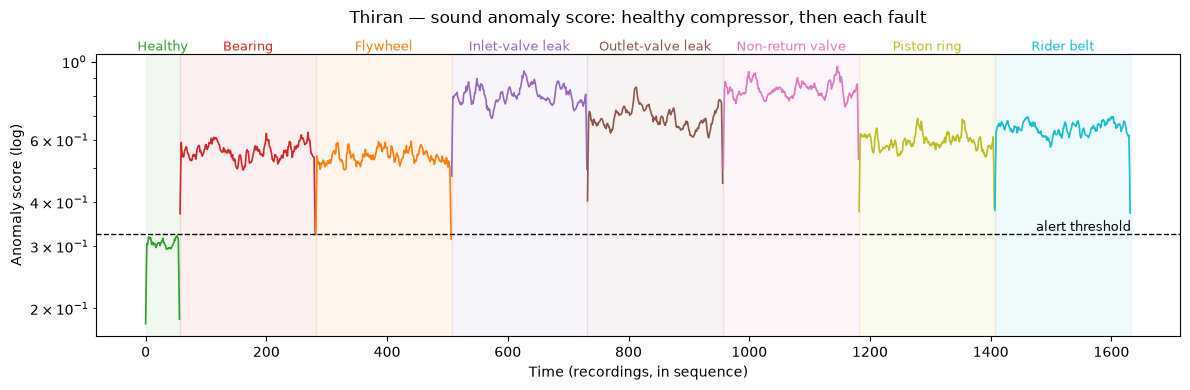

In [6]:
if PART_B:
    def mel_feats(path, ctx=5):
        y, sr = librosa.load(path, sr=16000)
        m = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=512, n_mels=64)).T
        return np.lib.stride_tricks.sliding_window_view(m, (ctx, 64))[:, 0].reshape(-1, ctx * 64).astype(np.float32)

    NAMES = {'LIV': 'Inlet-valve leak', 'LOV': 'Outlet-valve leak', 'NRV': 'Non-return valve',
             'Piston': 'Piston ring', 'Riderbelt': 'Rider belt'}
    by_cls = {}
    for w in sorted(wavs):
        c = os.path.basename(os.path.dirname(w)); by_cls.setdefault(NAMES.get(c, c), []).append(w)
    print({k: len(v) for k, v in by_cls.items()})
    healthy = by_cls.pop('Healthy'); rng = np.random.default_rng(0); rng.shuffle(healthy)
    a, b = int(0.6 * len(healthy)), int(0.75 * len(healthy))
    h_tr, h_va, h_te = healthy[:a], healthy[a:b], healthy[b:]

    Xtr = np.vstack([mel_feats(p) for p in h_tr])
    muB, sdB = Xtr.mean(0), Xtr.std(0) + 1e-6
    zB = lambda X: (X - muB) / sdB
    mB = train_ae(zB(Xtr), epochs=30, bs=256)
    clip = lambda p: anomaly_score(mB, zB(mel_feats(p))).mean()
    thrB = np.percentile([clip(p) for p in h_va], 99)
    sB_norm = np.array([clip(p) for p in h_te])
    sB_fault = {k: np.array([clip(p) for p in v]) for k, v in by_cls.items()}
    rowsB, faB = report('PART B — Sound (air compressor)', sB_norm, sB_fault, thrB)
    timeline(sB_norm, sB_fault, thrB, 'Thiran — sound anomaly score: healthy compressor, then each fault',
             'results/aircomp_timeline.png', unit='recording')

## Phone-readiness and summary

In [7]:
n_par = sum(p.numel() for p in mA.parameters())
print(f'Vibration model parameters: {n_par:,}  ->  {n_par*4/1024:.1f} KB (float32), ~{n_par/1024:.1f} KB (INT8)')

L = ['### Vibration — CWRU bearing dataset', '',
     '| Condition | ROC-AUC | Detection rate |', '|---|:---:|:---:|']
L += [f'| {k} | {a:.3f} | {d:.1f}% |' for k, a, d in rowsA]
L += [f'| False alarms on healthy data | – | {faA:.1f}% |', '', '![Vibration anomaly timeline](results/cwru_timeline.png)', '',
      '### Stress test — added factory noise (vibration)', '',
      'Background noise added to every signal; the model re-learns "normal" in the noisy setting, as it would on a real shop floor.', '',
      '| Noise level (SNR) | Mean ROC-AUC | Detection rate | False alarms |', '|---|:---:|:---:|:---:|']
L += [f'| {snr} dB | {a:.3f} | {d:.1f}% | {f:.1f}% |' for snr, a, d, f in rows_snr]
L += ['', '![Noise robustness](results/noise_robustness.png)', '']
if PART_B:
    L += ['### Sound — industrial air-compressor dataset', '',
          '| Condition | ROC-AUC | Detection rate |', '|---|:---:|:---:|']
    L += [f'| {k} | {a:.3f} | {d:.1f}% |' for k, a, d in rowsB]
    L += [f'| False alarms on healthy data | – | {faB:.1f}% |', '', '![Sound anomaly timeline](results/aircomp_timeline.png)', '']
L += [f'**Model size:** {n_par:,} parameters (~{n_par/1024:.0f} KB in INT8), small enough to run in real time, offline, on a low-cost phone.']
md_out = '\n'.join(L)
open('results/summary.md', 'w').write(md_out); print(md_out)
if os.path.exists('README.md'):
    rd = open('README.md').read(); a, b = '<!-- RESULTS:START -->', '<!-- RESULTS:END -->'
    if a in rd and b in rd:
        open('README.md', 'w').write(rd[:rd.index(a) + len(a)] + '\n' + md_out + '\n' + rd[rd.index(b):])
        print('\nREADME.md results updated.')

Vibration model parameters: 18,704  ->  73.1 KB (float32), ~18.3 KB (INT8)
### Vibration — CWRU bearing dataset

| Condition | ROC-AUC | Detection rate |
|---|:---:|:---:|
| Inner-race fault | 1.000 | 100.0% |
| Ball fault | 1.000 | 100.0% |
| Outer-race fault | 1.000 | 100.0% |
| False alarms on healthy data | – | 0.0% |

![Vibration anomaly timeline](results/cwru_timeline.png)

### Stress test — added factory noise (vibration)

Background noise added to every signal; the model re-learns "normal" in the noisy setting, as it would on a real shop floor.

| Noise level (SNR) | Mean ROC-AUC | Detection rate | False alarms |
|---|:---:|:---:|:---:|
| 10 dB | 1.000 | 100.0% | 0.0% |
| 0 dB | 1.000 | 100.0% | 0.0% |
| -5 dB | 1.000 | 100.0% | 0.0% |
| -10 dB | 1.000 | 100.0% | 0.0% |
| -15 dB | 0.976 | 82.9% | 0.0% |
| -20 dB | 0.830 | 43.8% | 0.0% |

![Noise robustness](results/noise_robustness.png)

### Sound — industrial air-compressor dataset

| Condition | ROC-AUC | Detection rate |
|--